# Modeling Experiments

We perform some modeling experiments using various models. In the modeling experiment process, we only use the training set that we had obtained from earlier to do our work. 
We avoid peaking on the test set in [data/cleaned_data/test.csv](data/cleaned_data/test.csv). We perform analysis of the most relevant features as we proceed in the modeling experiments and continue with exploratory data analysis.

Our original base line model in [models/modeling_baselines.ipynb](models/modeling_baselines.ipynb) utilized the training and test split there. Here we take that training set and had it split into a new training set and a new validation set since we not want to peak at our final evaluation metric. The baseline model we had originally was a Logistic Regression model. It had limited feature engineering and did not utilize any informed imputation methods.

In [31]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, log_loss, 
                             classification_report, average_precision_score, precision_recall_curve)

from preprocessing import import_data
from scoring import score
import matplotlib.pyplot as plt


import warnings
warnings.filterwarnings("ignore")

# Train/Validation Split and Import Data

In [8]:
def train_val_split_data(x=False):

    if x==True:
        # Import the cleaned_data

        train = pd.read_csv("../data/cleaned_data/train.csv")
        X = train.drop(columns="target")
        y = train["target"]

        # The target is imbalanced. We also want to keep repeat patients together.

        # 1. Set n_splits=5 so the test size naturally becomes 1/5 = 20%
        sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

        # 2. Get the indices for the very first split next() gets only the first split for us
        train_idx, test_idx = next(sgkf.split(X, y, groups=X['patient_nbr']))

        # 3. Create a single train/test split
        Xt, Xv = X.iloc[train_idx], X.iloc[test_idx]
        yt, yv = y.iloc[train_idx], y.iloc[test_idx]


        # We will save the train / validation split here and use it for the modeling experiments

        train = Xt.copy()
        train["target"] = yt
        train.to_csv("modeling_data/train.csv",index=False)

        validation = Xv.copy()
        validation["target"] = yv 
        validation.to_csv("modeling_data/validation.csv",index=False)
    else:
        return
    
train_val_split_data(x=False)


# XGBoost Classifier

For helpful information regarding XGBoost Classifier, see https://xgboosting.com/

In [9]:
import xgboost as xgb
Xt,yt,Xv,yv = import_data()

Importing train/validation data...
Finished the import.


In [10]:
# Define XGBClassifier model parameters

spw = (yt == 0).sum() / (yt == 1).sum()   

params = {
    'objective': 'binary:logistic',
    'eval_metric': 'aucpr',       # Optimizes for the Precision-Recall curve, not logloss
    'learning_rate': 0.01,
    'n_estimators': 1_500,
    'max_depth': 6,              # Controls model complexity
    'subsample': 0.5,            # Ensures % of rows are seen per tree so minority data isn't missed
    'colsample_bytree': 0.5,     # Ensures % of features are available to find rare predictors
    'min_child_weight': 3,       # Low enough to capture small minority pockets, high enough to filter pure noise
    'scale_pos_weight': spw * 2, # Aggressively forces recall by doubling the baseline ratio for F2
    'enable_categorical': True,
    'random_state': 42,
}

num_cols = Xt.select_dtypes(include=["number", "bool"]).columns
cat_cols = [c for c in Xt.columns if c not in num_cols]

# Drop columns that are constant in training (decided from training only)
const_cols = [c for c in cat_cols if Xt[c].nunique(dropna=False) <= 1]
Xt = Xt.drop(columns=const_cols)
Xv = Xv.drop(columns=const_cols)
cat_cols = [c for c in cat_cols if c not in const_cols]

# Categories come from the training set; unseen levels in Xv become NaN
Xt = Xt.copy()
Xv = Xv.copy()
for c in cat_cols:
    dtype = pd.CategoricalDtype(categories=Xt[c].dropna().unique())
    Xt[c] = Xt[c].astype(dtype)
    Xv[c] = Xv[c].astype(dtype)

# Instantiate XGBClassifier with the parameters
model = xgb.XGBClassifier(**params)

# Train the model
model.fit(Xt, yt)

# Make predicted probabilities on the test set
probs = model.predict_proba(Xv)[:,1]

In [11]:
score(yv,y_pred=None,proba=probs,threshold=0.65)

Accuracy: 0.700
Confusion matrix:
 [[10540  3926]
 [  952   865]]
              precision    recall  f1-score   support

           0       0.92      0.73      0.81     14466
           1       0.18      0.48      0.26      1817

    accuracy                           0.70     16283
   macro avg       0.55      0.60      0.54     16283
weighted avg       0.83      0.70      0.75     16283

F1 @0.65: 0.262
F2 @0.65: 0.359
ROC-AUC: 0.6292
PR-AUC:  0.2009

Best-threshold F1: 0.26313 at threshold 0.70034.

Best-threshold F2: 0.39261 at threshold 0.11102.


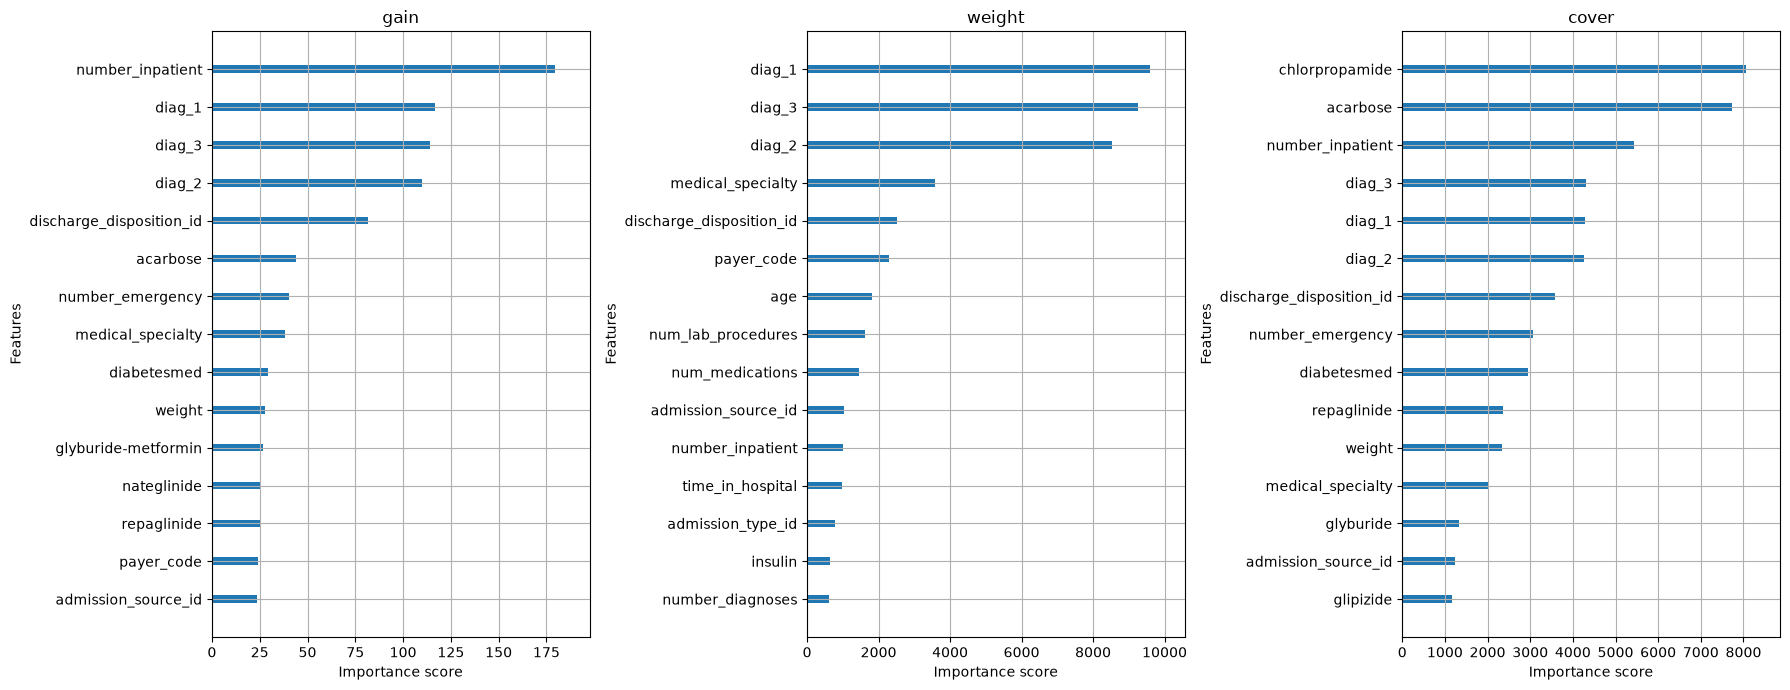

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, t in zip(axes, ["gain", "weight", "cover"]):
    xgb.plot_importance(model, importance_type=t, max_num_features=15, ax=ax, title=t, show_values=False)
plt.tight_layout()
plt.show()

# Logistic Regression Again

In [13]:
from sklearn.linear_model import LogisticRegression
Xt,yt,Xv,yv = import_data()

Importing train/validation data...
Finished the import.


In [14]:
num_cols = Xt.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = Xt.select_dtypes(include=['object','category']).columns.tolist()
features = num_cols+cat_cols

print(num_cols)
print(cat_cols)

['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
['race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'a1cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesmed']


In [15]:
# We use pipelines to make the feature selection and data cleaning process quicker

num = Pipeline([("imp", SimpleImputer(strategy="median")),("scale", StandardScaler())])
cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",min_frequency=20))])
prep = ColumnTransformer([("num", num, num_cols),("cat", cat, cat_cols)])
clf = Pipeline([("prep", prep), ("model", LogisticRegression(class_weight={0: 1, 1: 12}, max_iter=1000, random_state=42))])

In [16]:
# Fit the model to the training data
clf.fit(Xt,yt)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](47,)","['time_in_hospital','num_lab_procedures','num_procedures',..., 'metformin-pioglitazone','change','diabetesmed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,47
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying `

In [17]:
probs = clf.predict_proba(Xv)[:,1]
score(yv, y_pred=None, proba=probs, threshold=0.25)

Accuracy: 0.161
Confusion matrix:
 [[  827 13639]
 [   25  1792]]
              precision    recall  f1-score   support

           0       0.97      0.06      0.11     14466
           1       0.12      0.99      0.21      1817

    accuracy                           0.16     16283
   macro avg       0.54      0.52      0.16     16283
weighted avg       0.88      0.16      0.12     16283

F1 @0.25: 0.208
F2 @0.25: 0.395
ROC-AUC: 0.6569
PR-AUC:  0.2148

Best-threshold F1: 0.27597 at threshold 0.67794.

Best-threshold F2: 0.40925 at threshold 0.43369.


# CatBoost

We consider a catboost model.

In [18]:
from catboost import CatBoostClassifier
Xt,yt,Xv,yv = import_data()

Importing train/validation data...
Finished the import.


In [19]:
# prepare for catboost
num_cols = Xt.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = [c for c in Xt.columns if c not in num_cols]


# careful!! catboost demands categorical columns to have string entry
Xt_cb, Xv_cb = Xt.copy(), Xv.copy()
for c in cat_cols:
    for df in (Xt_cb, Xv_cb):
        df[c] = df[c].astype(object).where(df[c].notna(), "missing").astype(str)


# fitting to the training set, we determine the scale positive weight it resolves the class imbalance 
spw = (yt == 0).sum() / (yt == 1).sum()

model = CatBoostClassifier(
    iterations=2_500,
    learning_rate=0.01,
    depth=7,
    l2_leaf_reg=6,
    scale_pos_weight=spw,
    bootstrap_type="No",
    random_strength=1.0,
    loss_function="Logloss",
    eval_metric= "F:beta=2",
    random_seed=42,
    verbose=100,
    allow_writing_files=False,
)

model.fit(Xt_cb, yt, cat_features=cat_cols)

0:	learn: 0.6551374	total: 277ms	remaining: 11m 32s
100:	learn: 0.6112447	total: 15.9s	remaining: 6m 18s
200:	learn: 0.6145914	total: 32s	remaining: 6m 5s
300:	learn: 0.6131441	total: 48.3s	remaining: 5m 52s
400:	learn: 0.6159470	total: 1m 4s	remaining: 5m 39s
500:	learn: 0.6181848	total: 1m 23s	remaining: 5m 34s
600:	learn: 0.6203269	total: 1m 42s	remaining: 5m 23s
700:	learn: 0.6215515	total: 2m	remaining: 5m 8s
800:	learn: 0.6244741	total: 2m 17s	remaining: 4m 51s
900:	learn: 0.6265047	total: 2m 34s	remaining: 4m 34s
1000:	learn: 0.6282896	total: 2m 51s	remaining: 4m 16s
1100:	learn: 0.6295765	total: 3m 8s	remaining: 3m 59s
1200:	learn: 0.6334890	total: 3m 28s	remaining: 3m 45s
1300:	learn: 0.6364501	total: 3m 48s	remaining: 3m 30s
1400:	learn: 0.6412219	total: 4m 9s	remaining: 3m 15s
1500:	learn: 0.6441880	total: 4m 28s	remaining: 2m 58s
1600:	learn: 0.6472811	total: 4m 48s	remaining: 2m 41s
1700:	learn: 0.6498821	total: 5m 7s	remaining: 2m 24s
1800:	learn: 0.6553422	total: 5m 27s	

CatBoostClassifier(allow_writing_files=False, bootstrap_type='No', depth=7, eval_metric='F:beta=2', iterations=2500, l2_leaf_reg=6, learning_rate=0.01, loss_function='Logloss', random_seed=42, random_strength=1.0, scale_pos_weight=np.float64(7.9610621904237755), verbose=100)

In [20]:
proba = model.predict_proba(Xv_cb)[:, 1]
score(yv, y_pred=None, proba=proba, threshold=0.31273)

Accuracy: 0.289
Confusion matrix:
 [[ 3033 11433]
 [  137  1680]]
              precision    recall  f1-score   support

           0       0.96      0.21      0.34     14466
           1       0.13      0.92      0.23      1817

    accuracy                           0.29     16283
   macro avg       0.54      0.57      0.28     16283
weighted avg       0.86      0.29      0.33     16283

F1 @0.31273: 0.225
F2 @0.31273: 0.412
ROC-AUC: 0.6879
PR-AUC:  0.246

Best-threshold F1: 0.30024 at threshold 0.54682.

Best-threshold F2: 0.42915 at threshold 0.43757.


In [21]:
from catboost import Pool

print(model.get_param('class_weights'))


None


# LightGBM

In [22]:
import lightgbm as lgb 
Xt,yt,Xv,yv = import_data()

Importing train/validation data...
Finished the import.


In [23]:
# prepare for lgb
num_cols = Xt.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = [c for c in Xt.columns if c not in num_cols]

Xt_lgb, Xv_lgb = Xt.copy(), Xv.copy()
for c in cat_cols:
    dtype = pd.CategoricalDtype(categories=Xt[c].dropna().astype(str).unique())
    Xt_lgb[c] = Xt[c].astype(str).astype(dtype)
    Xv_lgb[c] = Xv[c].astype(str).astype(dtype)


const = [c for c in Xt.columns if Xt[c].nunique(dropna=False) <= 1]

# near-constant: >99.5% one value
near_const = [c for c in Xt.columns
              if Xt[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.995]

model = lgb.LGBMClassifier(
    n_estimators= 1_000,
    learning_rate=0.05,
    num_leaves=35,
    min_child_samples=50,
    subsample=0.8, 
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_lambda=15,
    cat_smooth=65,          # regularizes rare category levels
    min_data_per_group=1_000, # ensure enough data per group is used 
    is_unbalance=True,   # do this instead of spw
    random_state=42,
    verbose=-1,
)
model.fit(Xt_lgb, yt)   # pandas 'category' columns are detected automatically

,num_leaves,35
,learning_rate,0.05
,n_estimators,1000
,min_child_samples,50
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.7
,reg_lambda,15
,random_state,42
,cat_smooth,65
,min_data_per_group,1000


In [24]:
# Check feature importance
imp = pd.Series(model.booster_.feature_importance(importance_type="gain"),
                index=Xt_lgb.columns).sort_values(ascending=False)

print(f"Top Ten Most Important Features by Gain")
print(imp[0:10])

Top Ten Most Important Features by Gain
diag_1                      118007.790998
diag_3                       97627.963566
diag_2                       97135.397853
num_lab_procedures           84395.399544
num_medications              64837.888471
number_inpatient             51211.520001
discharge_disposition_id     42027.954714
time_in_hospital             40798.959877
age                          26636.560431
number_diagnoses             26501.909645
dtype: float64


In [25]:
proba = model.predict_proba(Xv_lgb)[:, 1]
score(yv, y_pred=None, proba=proba, threshold=0.58)

Accuracy: 0.827
Confusion matrix:
 [[12979  1487]
 [ 1323   494]]
              precision    recall  f1-score   support

           0       0.91      0.90      0.90     14466
           1       0.25      0.27      0.26      1817

    accuracy                           0.83     16283
   macro avg       0.58      0.58      0.58     16283
weighted avg       0.83      0.83      0.83     16283

F1 @0.58: 0.26
F2 @0.58: 0.267
ROC-AUC: 0.6664
PR-AUC:  0.2147

Best-threshold F1: 0.27596 at threshold 0.44251.

Best-threshold F2: 0.42127 at threshold 0.22042.


# RandomForest Classifier

In [32]:
from sklearn.ensemble import RandomForestClassifier
Xt,yt,Xv,yv = import_data()

Importing train/validation data...
Finished the import.


In [33]:
num_cols = Xt.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = Xt.select_dtypes(include=['object','category']).columns.tolist()
features = num_cols+cat_cols

In [34]:
# We use pipelines to make the feature selection and data cleaning process quicker

num = Pipeline([("imp", SimpleImputer(strategy="median")),("scale", StandardScaler())])
cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",min_frequency=20))])
prep = ColumnTransformer([("num", num, num_cols),("cat", cat, cat_cols)])
clf = Pipeline([("prep", prep), ("model", RandomForestClassifier(n_estimators=1000, random_state=42, n_jobs=-1, class_weight='balanced'))])


In [35]:
# Fit the model to the training data
clf.fit(Xt,yt)

# Have the model now make predictions
labels = clf.predict(Xv)

In [36]:
probs = clf.predict_proba(Xv)[:,1]
score(yv, y_pred=None, proba=probs, threshold=0.58)

Accuracy: 0.889
Confusion matrix:
 [[14457     9]
 [ 1804    13]]
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     14466
           1       0.59      0.01      0.01      1817

    accuracy                           0.89     16283
   macro avg       0.74      0.50      0.48     16283
weighted avg       0.86      0.89      0.84     16283

F1 @0.58: 0.014
F2 @0.58: 0.009
ROC-AUC: 0.6767
PR-AUC:  0.2329

Best-threshold F1: 0.29175 at threshold 0.27700.

Best-threshold F2: 0.42394 at threshold 0.17200.


# Conclusions

So far, it seems like CatBoost is able to provide the best F1-Scores. It's $F_1$-score with probability $0.58$ is $0.2986$. This is marginally better than the $F_1$-score of $0.2773$ that our modeling baseline gets. Furthermore, here, the threshold is $0.58$ meanwhile the modeling baseline had to use threshold $0.1380$ for its best score.